# Демо 1. Ембединги й семантичний пошук

У цьому ноутбуці перетворюємо тексти на **ембединги**. Ембединги — це вектори, у які перетворюються тексти таким чином, що близькі за значенням тексти мають вектори близькі за розміщенням у векторному просторі. На базі цієї властивості будуємо семантичний пошук. З метою навчання робимо це без жодних спеціалізованих бібліотек,
використовуємо лише `numpy`.

Документи для пошуку — нормативні документи Житомирської політехніки з [docs.ztu.edu.ua](https://docs.ztu.edu.ua/):
положення про оцінювання, гуртожитки, стипендії, старосту академічної групи тощо.
Мовна модель, яка потім буде використовуватися для генерації, швидше за все не бачила цих документів під час тренування, тому відповісти на питання про них
вона зможе лише тоді, коли потрібний фрагмент документа буде знайдено й передано їй у промпті.
Пошук потрібних фрагментів документа і є першою половиною RAG.

_Зверніть увагу: ноутбук працює і на CPU, але з GPU ембединги рахуються швидше._

In [14]:
# sentence-transformers — бібліотека для обчислення ембедингів текстів, pypdf — витягування тексту з PDF
!pip install -q "sentence-transformers>=5" pypdf

In [15]:
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import requests
import torch
from pypdf import PdfReader
from sentence_transformers import SentenceTransformer

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Пристрій: {device}")

Пристрій: cuda


## 1. Модель ембедингів

Для перетворення текстових фрагментів на ембединги використовують спеціальні ембедингові моделі. [Qwen3-Embedding-0.6B](https://huggingface.co/Qwen/Qwen3-Embedding-0.6B) — багатомовна модель ембедингів із сімʼї моделей Qwen3. Вона перетворює текст довжиною до ~32 тис. токенів на вектор
із 1024 чисел. Ці два числа: максимальний розмір вхідного тексту і розмірність результуючого ембедингу - є важливими характеристиками ембедингових моделей.

In [16]:
EMBEDDING_MODEL_NAME = "Qwen/Qwen3-Embedding-0.6B"
dtype = torch.float16 if device == "cuda" else torch.float32
model = SentenceTransformer(EMBEDDING_MODEL_NAME, device=device, model_kwargs={"dtype": dtype})

print(f"Розмірність ембедингу: {model.get_sentence_embedding_dimension()}")
print(f"Максимальна довжина тексту в токенах: {model.max_seq_length}")

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Розмірність ембедингу: 1024
Максимальна довжина тексту в токенах: 32768


/tmp/ipykernel_757/1793327947.py:5: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print(f"Розмірність ембедингу: {model.get_sentence_embedding_dimension()}")


## 2. Ембединг одного речення

Незалежно від довжини тексту модель повертає вектор однакової розмірності.
Параметр `normalize_embeddings=True` ділить вектор на його евклідову ($L_{2}$) норму. Формула евклідової норми:

$$
\|\vec{x}\|_{2} = \sqrt{\sum_{i=1}^{n}x_{i}^{2}}
$$


Таким чином довжина (норма) вектора дорівнює 1.
Так косинусна подібність, яку потім потрібно часто підраховувати, зводиться до скалярного добутку.

In [17]:
sentence = "Чому я такий розумний?"
embedding = model.encode(sentence, normalize_embeddings=True)

print(f"Форма: {embedding.shape}")
print(f"Перші 8 чисел: {embedding[:8]}")
print(f"Евклідова норма вектора: {np.linalg.norm(embedding):.4f}")

# Загалом модель сама нормалізує вектор всередині,
# тому `normalize_embeddings=True` є зайвим у цьому конкретному випадку
# зверніть увагу на останній шар моделі
print(model)

Форма: (1024,)
Перші 8 чисел: [-0.02551   -0.09235   -0.0002925  0.02061    0.007275   0.0573
 -0.0488     0.04395  ]
Евклідова норма вектора: 1.0000
SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'Qwen3Model'})
  (1): Pooling({'embedding_dimension': 1024, 'pooling_mode': 'lasttoken', 'include_prompt': True})
  (2): Normalize({})
)


## 3. Косинусна подібність

Близькість двох ембедингів вимірюють **косинусом кута** між ними:

$$\cos(a, b) = \frac{a \cdot b}{\|a\| \, \|b\|}$$

Значення `1` означає однаковий напрям векторів, `0` — ортогональні вектори, `-1` - вектори вказують у повністю протилежні сторони.
Для нормалізованих векторів знаменник дорівнює 1, і косинус дорівнює скалярному добутку.
Порахуємо його вручну й порівняємо з вбудованим методом `model.similarity`.

In [18]:
a, b, c = model.encode(
    ["Скільки коштує проживання в гуртожитку?",
     "Яка плата за місце в студентському гуртожитку?",
     "Чому Політехніка краще за Гарвард?"],
    normalize_embeddings=True,
)

manual = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
with_library = model.similarity(a, b).item()

print(f"Вручну (a <=> b):     {manual:.4f}")
print(f"Бібліотека (a <=> b): {with_library:.4f}")

print(f"Бібліотека (a <=> c): {model.similarity(a, c).item():.4f}")

Вручну (a <=> b):     0.6489
Бібліотека (a <=> b): 0.6489
Бібліотека (a <=> c): 0.2329


In [19]:
# Оскільки, як зазначалося вище, ембединги є зазвичай нормалізованими векторами, то знаменник дорівнює `1`.
# Перевіримо це:
print(f"Норма a: {np.linalg.norm(a):.4f}")
print(f"Норма b: {np.linalg.norm(b):.4f}")
print(f"Норма c: {np.linalg.norm(c):.4f}")

Норма a: 1.0000
Норма b: 1.0000
Норма c: 1.0000


In [20]:
# Зважаючи на це ми можемо опускати нижню частину формули косинусної подібності
# і вираховувати її лише як скалярний добуток двох векторів

pure_dot_product = np.dot(a, b)
vector_norm_product = np.linalg.norm(a) * np.linalg.norm(b)

assert round(pure_dot_product, 4) == round(manual, 4) == round(with_library, 4), "The teacher made a mistake!"
assert np.isclose(vector_norm_product, 1), "The teacher doesn't know math"

### Косинусна подібність на простих векторах

Ембединг має 1024 виміри, але формула однакова для будь-якої розмірності.
Розглянемо її на двовимірних векторах, які можна намалювати. Вектор $a = (3, 1)$ порівнюємо з чотирма іншими:
- $e = (6, 2)$ — той самий напрям, але вдвічі довший;
- $b = (2, 2)$ — близький напрям;
- $c = (-1, 3)$ — перпендикулярний напрям;
- $d = (-3, -1)$ — протилежний напрям.

a·e =   20   ‖a‖·‖e‖ = 20.00   cos =  1.00   кут =   0.0°
a·b =    8   ‖a‖·‖b‖ =  8.94   cos =  0.89   кут =  26.6°
a·c =    0   ‖a‖·‖c‖ = 10.00   cos =  0.00   кут =  90.0°
a·d =  -10   ‖a‖·‖d‖ = 10.00   cos = -1.00   кут = 180.0°


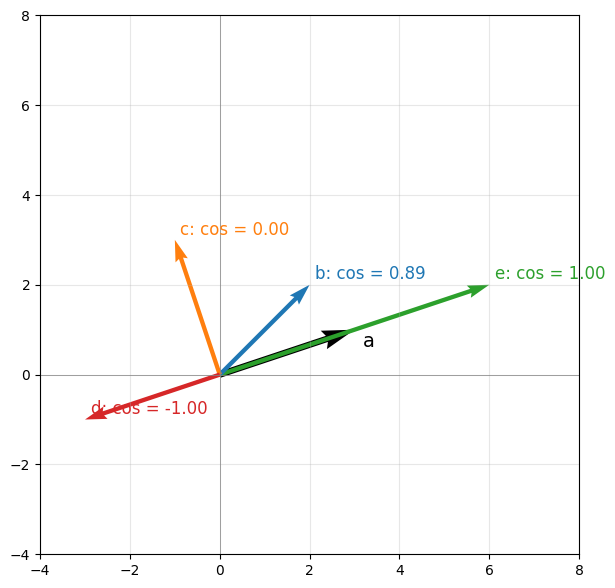

In [21]:
a2 = np.array([3, 1])
others = {
    "e": np.array([6, 2]),
    "b": np.array([2, 2]),
    "c": np.array([-1, 3]),
    "d": np.array([-3, -1]),
}


def cosine(u, v):
    return np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))


for name, v in others.items():
    dot = np.dot(a2, v)
    norms = np.linalg.norm(a2) * np.linalg.norm(v)
    angle = np.degrees(np.arccos(np.clip(cosine(a2, v), -1, 1)))
    print(f"a·{name} = {dot:4}   ‖a‖·‖{name}‖ = {norms:5.2f}   cos = {dot / norms:5.2f}   кут = {angle:5.1f}°")

fig, ax = plt.subplots(figsize=(7, 7))
ax.quiver(0, 0, *a2, angles="xy", scale_units="xy", scale=1, color="black", width=0.012)
ax.annotate("a", a2, xytext=(6, -12), textcoords="offset points", fontsize=14)
for (name, v), color in zip(others.items(), ["tab:green", "tab:blue", "tab:orange", "tab:red"]):
    ax.quiver(0, 0, *v, angles="xy", scale_units="xy", scale=1, color=color, width=0.008)
    ax.annotate(f"{name}: cos = {cosine(a2, v):.2f}", v, xytext=(4, 4), textcoords="offset points",
                fontsize=12, color=color)
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
ax.set_xlim(-4, 8)
ax.set_ylim(-4, 8)
ax.set_aspect("equal")
ax.grid(alpha=0.3)
plt.show()

Косинус залежить лише від кута між векторами, а не від їхньої довжини: вектор $e$ удвічі довший за $a$,
але косинус дорівнює 1. Знаменник формули саме й прибирає вплив довжини.

Тепер нормалізуємо всі вектори — поділимо кожен на його довжину. Кінці нормалізованих векторів лежать
на колі радіуса 1, напрями не змінюються, а скалярний добуток дорівнює косинусу без жодного ділення.

e = [0.949 0.316]   довжина = 1.00   скалярний добуток =  1.00   cos =  1.00
b = [0.707 0.707]   довжина = 1.00   скалярний добуток =  0.89   cos =  0.89
c = [-0.316  0.949]   довжина = 1.00   скалярний добуток =  0.00   cos =  0.00
d = [-0.949 -0.316]   довжина = 1.00   скалярний добуток = -1.00   cos = -1.00


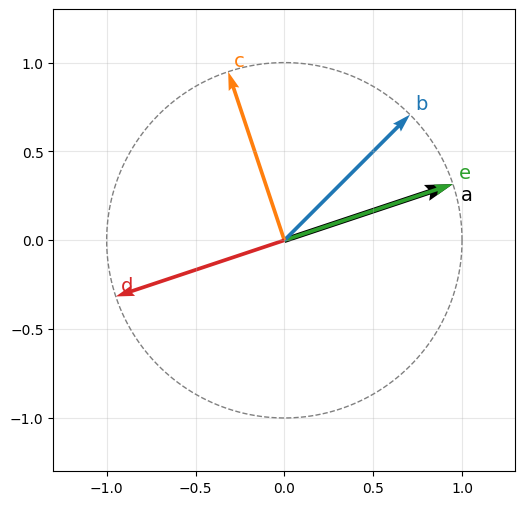

In [22]:
def normalize(v):
    return v / np.linalg.norm(v)


a2_unit = normalize(a2)
for name, v in others.items():
    v_unit = normalize(v)
    print(f"{name} = {np.round(v_unit, 3)}   довжина = {np.linalg.norm(v_unit):.2f}   "
          f"скалярний добуток = {np.dot(a2_unit, v_unit):5.2f}   cos = {cosine(a2, v):5.2f}")

fig, ax = plt.subplots(figsize=(6, 6))
circle = np.linspace(0, 2 * np.pi, 200)
ax.plot(np.cos(circle), np.sin(circle), color="grey", lw=1, ls="--")
ax.quiver(0, 0, *a2_unit, angles="xy", scale_units="xy", scale=1, color="black", width=0.012)
ax.annotate("a", a2_unit, xytext=(6, -12), textcoords="offset points", fontsize=14)
for (name, v), color in zip(others.items(), ["tab:green", "tab:blue", "tab:orange", "tab:red"]):
    v_unit = normalize(v)
    ax.quiver(0, 0, *v_unit, angles="xy", scale_units="xy", scale=1, color=color, width=0.008)
    ax.annotate(name, v_unit, xytext=(4, 4), textcoords="offset points", fontsize=14, color=color)
ax.set_xlim(-1.3, 1.3)
ax.set_ylim(-1.3, 1.3)
ax.set_aspect("equal")
ax.grid(alpha=0.3)
plt.show()

Вектори $a$ і $e$ після нормалізації збіглися: однаковий напрям — однаковий нормалізований вектор.

### Три виміри

У трьох вимірах усе так само: кожна компонента вектора — окрема вісь, скалярний добуток — сума
трьох попарних добутків. Нехай компоненти означають, наскільки текст стосується трьох тем:
гуртожитку, стипендії й погоди.

«плата за гуртожиток» і «заселення в гуртожиток»: a·b = 0.9·0.8 + 0.3·0.1 + 0.0·0.1 = 0.75, cos = 0.97
«плата за гуртожиток» і «стипендія»: a·b = 0.9·0.2 + 0.3·0.9 + 0.0·0.0 = 0.45, cos = 0.51
«плата за гуртожиток» і «погода»: a·b = 0.9·0.0 + 0.3·0.1 + 0.0·0.9 = 0.03, cos = 0.03


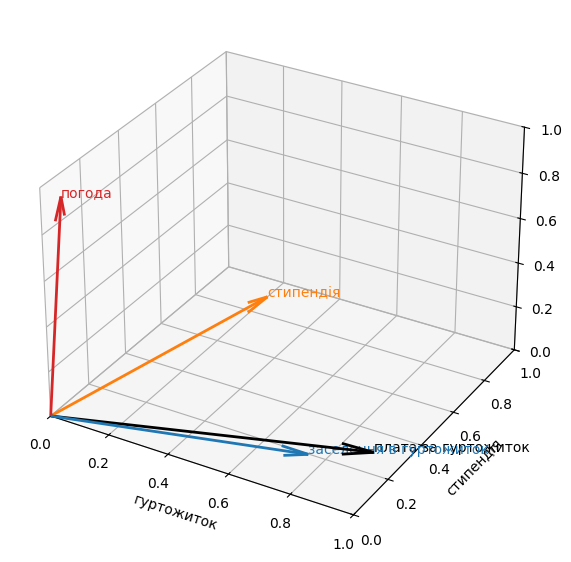

In [23]:
vectors_3d = {
    "плата за гуртожиток": np.array([0.9, 0.3, 0.0]),
    "заселення в гуртожиток": np.array([0.8, 0.1, 0.1]),
    "стипендія": np.array([0.2, 0.9, 0.0]),
    "погода": np.array([0.0, 0.1, 0.9]),
}
names_3d = list(vectors_3d)
query_3d = vectors_3d[names_3d[0]]
for name in names_3d[1:]:
    v = vectors_3d[name]
    products = " + ".join(f"{x:.1f}·{y:.1f}" for x, y in zip(query_3d, v))
    print(f"«{names_3d[0]}» і «{name}»: a·b = {products} = {np.dot(query_3d, v):.2f}, cos = {cosine(query_3d, v):.2f}")

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(projection="3d")
for (name, v), color in zip(vectors_3d.items(), ["black", "tab:blue", "tab:orange", "tab:red"]):
    ax.quiver(0, 0, 0, *v, color=color, arrow_length_ratio=0.1, linewidth=2)
    ax.text(*v, name, color=color, fontsize=10)
ax.set_xlabel("гуртожиток")
ax.set_ylabel("стипендія")
ax.set_zlabel("погода")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_zlim(0, 1)
plt.show()

Справжній ембединг влаштований так само, лише замість трьох осей — 1024. На відміну від цього прикладу,
окремі виміри ембединга не мають зрозумілого людині змісту: значення має лише напрям вектора в цілому.

## 4. Матриця подібності

Порахуємо подібність кожного речення з кожним. Серед речень є:
- дві пари перефразувань (про плату за гуртожиток і про стипендію);
- два речення зі спільним словом «ключ», але різним змістом;
- речення, не повʼязане з рештою.

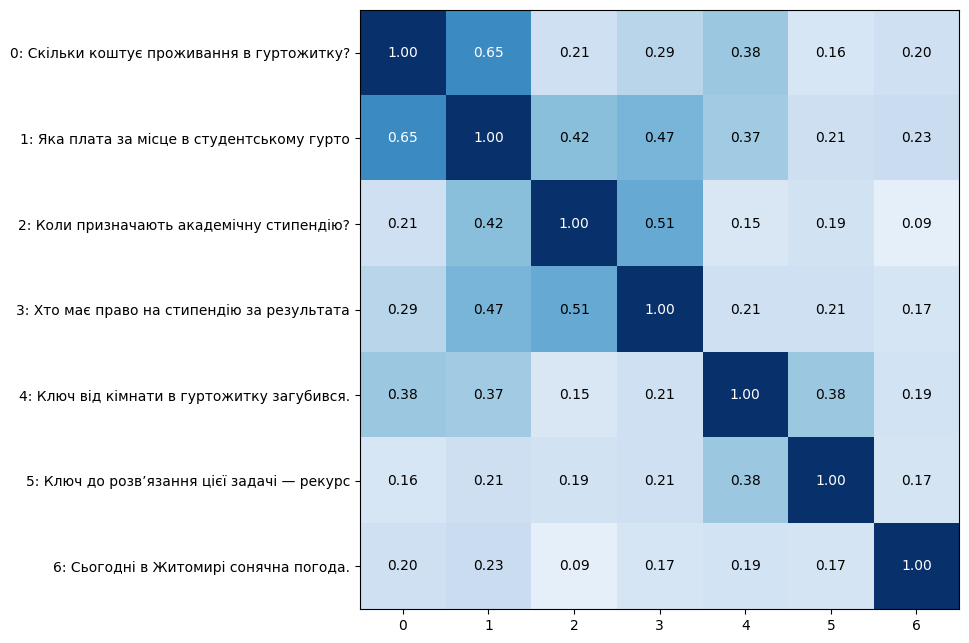

In [24]:
def show_similarity_matrix(sentences, figsize=(9, 7)):
  embeddings = model.encode(sentences, normalize_embeddings=True)
  similarity = embeddings @ embeddings.T

  fig, ax = plt.subplots(figsize=figsize)
  ax.imshow(similarity, cmap="Blues", vmin=0, vmax=1)
  ax.set_xticks(range(len(sentences)), [f"{i}" for i in range(len(sentences))])
  ax.set_yticks(range(len(sentences)), [f"{i}: {s[:40]}" for i, s in enumerate(sentences)])
  for i in range(len(sentences)):
      for j in range(len(sentences)):
          ax.text(j, i, f"{similarity[i, j]:.2f}", ha="center", va="center",
                  color="white" if similarity[i, j] > 0.6 else "black")
  plt.tight_layout()
  plt.show()

uni_sentences = [
    "Скільки коштує проживання в гуртожитку?",
    "Яка плата за місце в студентському гуртожитку?",
    "Коли призначають академічну стипендію?",
    "Хто має право на стипендію за результатами сесії?",
    "Ключ від кімнати в гуртожитку загубився.",
    "Ключ до розвʼязання цієї задачі — рекурсія.",
    "Сьогодні в Житомирі сонячна погода.",
]

show_similarity_matrix(uni_sentences)


Перефразування мають найвищу подібність, хоча містять лише одне спільне слово, так само як і пара з речень 4-5, схожість яких вдвічі менша.
Водночас подібність ніколи не падає до нуля: навіть речення про погоду має з рештою додатну подібність.

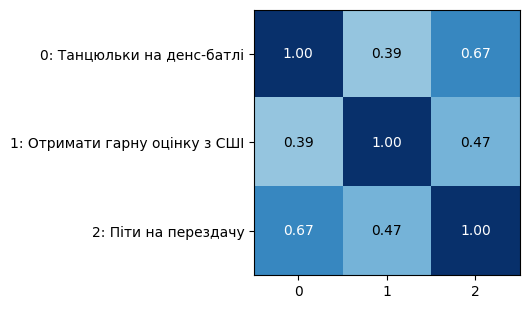

In [25]:
# Пограємося, вимірюючи подібність цілком випадкових і взагалі не придуманих викладачем фраз

pseudo_random_sentences = [
    "Танцюльки на денс-батлі",
    "Отримати гарну оцінку з СШІ",
    "Піти на перездачу"
]

show_similarity_matrix(pseudo_random_sentences, figsize=(5, 4))


## 5. Тексти на площині

Вектор із 1024 чисел неможливо намалювати, тому проєктуємо ембединги на площину методом головних компонент (Principal Component Analysis, PCA).
Проєкція втрачає більшу частину інформації, але групи речень на одну тему видно й на ній.

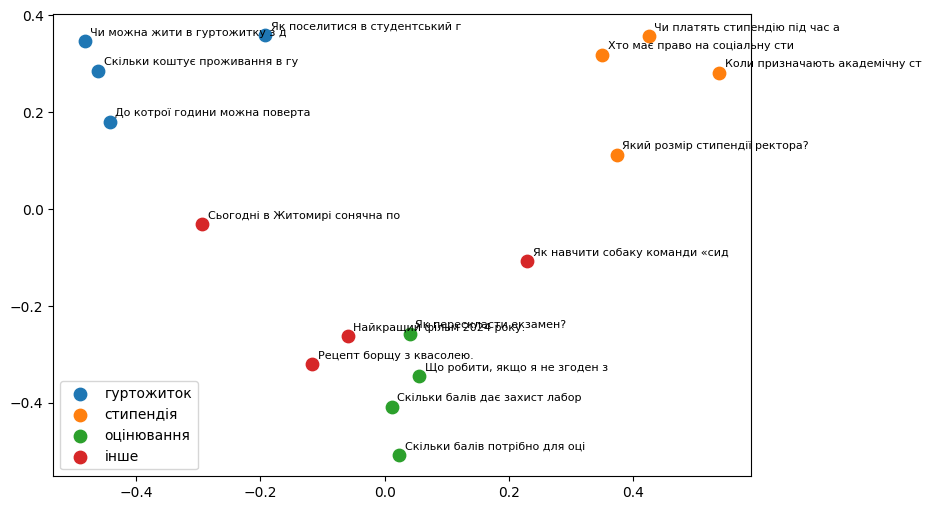

In [26]:
topics = {
    "гуртожиток": [
        "Скільки коштує проживання в гуртожитку?",
        "Як поселитися в студентський гуртожиток?",
        "До котрої години можна повертатися в гуртожиток?",
        "Чи можна жити в гуртожитку з дружиною?",
    ],
    "стипендія": [
        "Коли призначають академічну стипендію?",
        "Хто має право на соціальну стипендію?",
        "Який розмір стипендії ректора?",
        "Чи платять стипендію під час академічної відпустки?",
    ],
    "оцінювання": [
        "Скільки балів потрібно для оцінки «відмінно»?",
        "Що робити, якщо я не згоден з оцінкою?",
        "Як перескласти екзамен?",
        "Скільки балів дає захист лабораторної роботи?",
    ],
    "інше": [
        "Сьогодні в Житомирі сонячна погода.",
        "Рецепт борщу з квасолею.",
        "Найкращий фільм 2024 року.",
        "Як навчити собаку команди «сидіти»?",
    ],
}
texts = [t for group in topics.values() for t in group]
labels = [name for name, group in topics.items() for _ in group]
points = model.encode(texts, normalize_embeddings=True).astype(np.float32)  # linalg не підтримує float16

centered = points - points.mean(axis=0)
_, _, vt = np.linalg.svd(centered, full_matrices=False)
xy = centered @ vt[:2].T

fig, ax = plt.subplots(figsize=(9, 6))
for name in topics:
    mask = np.array(labels) == name
    ax.scatter(xy[mask, 0], xy[mask, 1], s=80, label=name)
for (x, y), t in zip(xy, texts):
    ax.annotate(t[:30], (x, y), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.legend()
plt.show()

## 6. Запит і документ кодуються по-різному

Короткий запит («до якої дати платити?») і фрагмент документа, що містить відповідь, — тексти різного вигляду.
Тому багато моделей ембедингів додають до запиту інструкцію. Qwen3-Embedding зберігає її у промпті `query`,
а документи кодує без інструкції.

In [27]:
print(repr(model.prompts["query"]))
print(repr(model.prompts["document"]))

'Instruct: Given a web search query, retrieve relevant passages that answer the query\nQuery:'
''


In [28]:
passages = [
    "Студент вносить авансовий платіж за 1 семестр до 1 вересня, а за 2 семестр – до 1 лютого.",
    "З 23:00 години і до 7:00 години в гуртожитку повинна додержуватись тиша.",
    "Вибори старости академічної групи на 1 курсі відбуваються після двох тижнів навчального процесу.",
    "Оцінка «добре» (B за шкалою ЄКТС) відповідає 82–89 балам.",
]
queries = [
    "До якої дати платити за гуртожиток?",
    "Коли в гуртожитку не можна шуміти?",
    "Коли обирають старосту?",
    "Скільки балів на B?",
]
passage_embeddings = model.encode(passages, normalize_embeddings=True)

np.set_printoptions(precision=2, suppress=True)
for prompt_name in [None, "query"]:
    query_embeddings = model.encode(queries, normalize_embeddings=True, prompt_name=prompt_name)
    print(f"Промпт запиту: {prompt_name}")
    print(query_embeddings @ passage_embeddings.T, "\n")

Промпт запиту: None
[[0.44 0.52 0.28 0.15]
 [0.17 0.69 0.22 0.15]
 [0.15 0.11 0.43 0.15]
 [0.2  0.16 0.16 0.38]] 

Промпт запиту: query
[[0.51 0.61 0.33 0.18]
 [0.2  0.76 0.24 0.15]
 [0.2  0.14 0.45 0.17]
 [0.19 0.17 0.17 0.4 ]] 



Рядки — запити, стовпці — фрагменти; на діагоналі стоїть правильна пара.

## 7. Документи університету

Завантажуємо 14 документів із сайту університету й витягуємо з них текст бібліотекою `pypdf`.
Серед них дві версії Положення про оцінювання — чинна і стара — та дві редакції освітньої програми
«Інженерія програмного забезпечення». Такі дублікати з різними даними типові для реальних баз документів.

In [29]:
BASE_URL = "https://docs.ztu.edu.ua/"
DOCUMENTS = [
    ("275", "Положення про оцінювання результатів навчання (чинна версія 4.0)", {"mdocs-file": 275}),
    ("275-v3.1", "Положення про оцінювання результатів навчання (стара версія 3.1)",
     {"mdocs-version": "polozhennja pro ocinjuvannja znan yekts_nove.pdf-v3.1", "mdocs-file": 275, "mdocs-url": "false"}),
    ("277", "Положення про порядок та умови обрання здобувачами вищої освіти навчальних дисциплін", {"mdocs-file": 277}),
    ("291", "Положення про проведення практики здобувачів вищої освіти", {"mdocs-file": 291}),
    ("340", "Правила призначення академічних стипендій", {"mdocs-file": 340}),
    ("344", "Положення про стипендію ректора", {"mdocs-file": 344}),
    ("348", "Положення про користування гуртожитками", {"mdocs-file": 348}),
    ("1219", "Правила внутрішнього розпорядку в студентських гуртожитках", {"mdocs-file": 1219}),
    ("1199", "Кодекс академічної доброчесності", {"mdocs-file": 1199}),
    ("4389", "Положення про студентського омбудсмана", {"mdocs-file": 4389}),
    ("336", "Положення про старосту академічної групи", {"mdocs-file": 336}),
    ("3320", "ОПП F2 «Інженерія програмного забезпечення» (бакалавр), редакція 2025 року", {"mdocs-file": 3320}),
    ("3329", "ОПП 121 «Інженерія програмного забезпечення» (бакалавр), редакція 2024 року", {"mdocs-file": 3329}),
    ("283", "Положення про переведення здобувачів вищої освіти", {"mdocs-file": 283}),
]


PDF_DIR = Path("ztu_pdfs")
PDF_DIR.mkdir(exist_ok=True)


def fetch(params, attempts=3):
    # Сайт іноді обриває зʼєднання, тому пробуємо кілька разів
    for attempt in range(attempts):
        try:
            response = requests.get(BASE_URL, params=params, timeout=120)
            response.raise_for_status()
            return response.content
        except requests.RequestException:
            if attempt == attempts - 1:
                raise
            time.sleep(5)


def download_pdf(doc_id, params):
    # Зберігаємо PDF на диск, щоб під час повторного запуску не завантажувати їх знову
    path = PDF_DIR / f"{doc_id}.pdf"
    if not path.exists():
        path.write_bytes(fetch(params))
    return PdfReader(path)

### Колонтитули

Кожна сторінка цих документів починається з однакового колонтитула системи управління якістю
(назва університету, код документа, номер аркуша). Прибираємо рядки колонтитула регулярним виразом.
Оформлення колонтитула в різних документах трохи відрізняється (регістр, формат коду документа), тому вираз
нечутливий до регістру й перевіряє лише перші 12 рядків сторінки, щоб не зачепити числа в таблицях.

In [30]:
HEADER_LINE = re.compile(
    r"^(Житомирська|політехніка|Міністерство освіти.*|Державний університет «Житомирська політехніка»|"
    r"Система управління якістю.*|П[\s\-–]*[CС]?[АA]?[ГG]?[\s\d.\-–]*|[\d.\-–\s/_]+|Випуск.*)$",
    re.IGNORECASE,
)
HEADER_LINES = 12


def page_text(page):
    lines = (page.extract_text() or "").split("\n")
    head = [line for line in lines[:HEADER_LINES] if not HEADER_LINE.match(line.strip())]
    return " ".join(head + lines[HEADER_LINES:])


reader = download_pdf("336", {"mdocs-file": 336})
print("До очищення:\n", reader.pages[2].extract_text()[:400])
print("\nПісля очищення:\n", page_text(reader.pages[2])[:400])

До очищення:
 Житомирська 
політехніка 
Міністерство освіти і науки України 
Державний університет «Житомирська політехніка» 
П CАГ – 44 – 15 – 02 – 
2019 
Випуск 2 Зміни 1 Екземпляр № 2 Арк   8/__ 
 
 3 
 
1. ЗАГАЛЬНІ ПОЛОЖЕННЯ 
1.1. Старостою академічної групи може бути студент, якому притаманні високі 
моральні якості, що користується авторитетом і повагою у своїх колег, має позитивний вплив 
на колектив гру

Після очищення:
     1. ЗАГАЛЬНІ ПОЛОЖЕННЯ  1.1. Старостою академічної групи може бути студент, якому притаманні високі  моральні якості, що користується авторитетом і повагою у своїх колег, має позитивний вплив  на колектив групи та володіє організаторськими здібностями.  1.2. Староста студентської академічної групи обирається як представник деканату для  організаційного забезпечення навчального процесу в академі


### Документи без текстового шару

Частина PDF — це відскановані сторінки: замість тексту в них зображення, і `pypdf` нічого не витягує.
Для таких документів потрібне розпізнавання тексту (OCR); у цьому демо ми їх просто пропускаємо.

In [31]:
MIN_CHARS_PER_PAGE = 100


def document_text(reader):
    return re.sub(r"\s+", " ", " ".join(page_text(page) for page in reader.pages)).strip()


def is_scan(text, reader):
    return len(text) < MIN_CHARS_PER_PAGE * len(reader.pages)


documents = {}
for doc_id, title, params in DOCUMENTS:
    reader = download_pdf(doc_id, params)
    text = document_text(reader)
    if is_scan(text, reader):
        print(f"{doc_id}: текстового шару немає, потрібне OCR — пропущено")
        continue
    documents[doc_id] = {"title": title, "text": text}
    print(f"{doc_id}: {len(reader.pages)} сторінок, {len(text)} символів — {title}")

275: 23 сторінок, 24944 символів — Положення про оцінювання результатів навчання (чинна версія 4.0)
275-v3.1: 13 сторінок, 10505 символів — Положення про оцінювання результатів навчання (стара версія 3.1)
277: 16 сторінок, 15945 символів — Положення про порядок та умови обрання здобувачами вищої освіти навчальних дисциплін
291: 17 сторінок, 14603 символів — Положення про проведення практики здобувачів вищої освіти
340: 30 сторінок, 35706 символів — Правила призначення академічних стипендій
344: 10 сторінок, 2455 символів — Положення про стипендію ректора
348: 22 сторінок, 25608 символів — Положення про користування гуртожитками
1219: 12 сторінок, 9159 символів — Правила внутрішнього розпорядку в студентських гуртожитках
1199: 37 сторінок, 56918 символів — Кодекс академічної доброчесності
4389: 18 сторінок, 20685 символів — Положення про студентського омбудсмана
336: 8 сторінок, 3560 символів — Положення про старосту академічної групи
3320: 16 сторінок, 31670 символів — ОПП F2 «Інженері

## 8. Пошук вручну

Цілий документ задовгий для одного ембединга: у вектор із 1024 чисел не вміститься зміст 30 сторінок.
Тому ділимо кожен документ на **фрагменти** по 1000 символів, що перекриваються на 200 символів,
щоб речення на межі потрапило хоча б в один фрагмент повністю. Зверніть увагу, це не є найоптимальнішим способом для таких документів. Способи розбиття детально розглядаємо в демо 2.

In [32]:
CHUNK_SIZE, OVERLAP = 1000, 200

chunks = []
for doc_id, doc in documents.items():
    text = doc["text"]
    for start in range(0, len(text), CHUNK_SIZE - OVERLAP):
        chunks.append({"doc_id": doc_id, "text": text[start:start + CHUNK_SIZE]})

print(f"Фрагментів: {len(chunks)}")
start = time.time()
chunk_embeddings = model.encode([c["text"] for c in chunks], normalize_embeddings=True,
                                batch_size=16, show_progress_bar=True)
print(f"Ембединги пораховано за {time.time() - start:.1f} с, форма матриці: {chunk_embeddings.shape}")

Фрагментів: 361


Batches:   0%|          | 0/23 [00:00<?, ?it/s]

Ембединги пораховано за 18.1 с, форма матриці: (361, 1024)


Увесь пошук — це одне множення матриці фрагментів на вектор запиту й сортування результатів.

In [33]:
def search(query, embeddings, k=3):
    query_embedding = model.encode(query, normalize_embeddings=True, prompt_name="query")
    scores = embeddings @ query_embedding
    top = np.argsort(-scores)[:k]
    return [(int(i), float(scores[i])) for i in top]


def show(query, embeddings, k=3):
    print(f"Запит: {query}")
    for i, score in search(query, embeddings, k):
        chunk = chunks[i]
        print(f"  {score:.2f}  [{chunk['doc_id']}] {documents[chunk['doc_id']]['title']}")
        print(f"        {chunk['text'][:150]}…")
    print()


show("Коли обирають старосту на першому курсі?", chunk_embeddings)
show("Хто такий студентський омбудсман?", chunk_embeddings)

Запит: Коли обирають старосту на першому курсі?
  0.57  [336] Положення про старосту академічної групи
         ректоратом або за їх дорученням. У своїй роботі староста академічної групи співпрацює з куратором та ментором групи. 1.3. У виборах старости студентс…
  0.50  [4389] Положення про студентського омбудсмана
        ємодіє з Молодіжною радою при Житомирській обласній державній (військовій) адміністрації та іншими консультативно-дорадчими органами молодіжної політи…
  0.50  [277] Положення про порядок та умови обрання здобувачами вищої освіти навчальних дисциплін
        нсульт Максим ОСТАПЧУК __.__.20__ Додаток 1 до Положення про порядок та умови обрання здобувачами вищої освіти вибіркових дисциплін (пункт 2.4.) Декан…

Запит: Хто такий студентський омбудсман?
  0.71  [4389] Положення про студентського омбудсмана
        ЗАТВЕРДЖЕНО Наказ Державного університету «Житомирська політехніка» 28 вересня 2026 р. № 453/од ПОЛОЖЕННЯ про студентського омбудсмана у Державному ун…
  0.71  

### Питання з відомими відповідями

Для кожного питання ми заздалегідь знаємо документ, у якому є відповідь.
Перевіримо, чи потрапляє фрагмент із цього документа до трьох найближчих.

In [34]:
QUESTIONS = [
    ("До якої дати потрібно оплатити гуртожиток за перший семестр?", "348"),
    ("Чи можна платити за гуртожиток щомісяця?", "348"),
    ("Чи можна жити в гуртожитку з дружиною?", "348"),
    ("З якої години в гуртожитку має бути тиша?", "1219"),
    ("Коли обирають старосту на першому курсі?", "336"),
    ("Скільки балів потрібно для оцінки «добре» B?", "275"),
    ("Що робити, якщо я не згоден з оцінкою за семестр?", "275"),
    ("Яку частку кредитів становлять вибіркові дисципліни?", "277"),
    ("Хто такий студентський омбудсман?", "4389"),
]


def check(embeddings, k=3):
    found = 0
    for question, gold in QUESTIONS:
        top_docs = [chunks[i]["doc_id"] for i, _ in search(question, embeddings, k)]
        hit = gold in top_docs
        found += hit
        print(f"{'✓' if hit else '✗'} {question}  очікуємо {gold}, знайдено {top_docs}")
    print(f"\nЗнайдено {found} з {len(QUESTIONS)}")


check(chunk_embeddings)

✓ До якої дати потрібно оплатити гуртожиток за перший семестр?  очікуємо 348, знайдено ['348', '348', '348']
✓ Чи можна платити за гуртожиток щомісяця?  очікуємо 348, знайдено ['348', '348', '348']
✓ Чи можна жити в гуртожитку з дружиною?  очікуємо 348, знайдено ['1219', '348', '1219']
✓ З якої години в гуртожитку має бути тиша?  очікуємо 1219, знайдено ['1219', '1219', '348']
✓ Коли обирають старосту на першому курсі?  очікуємо 336, знайдено ['336', '4389', '277']
✓ Скільки балів потрібно для оцінки «добре» B?  очікуємо 275, знайдено ['275-v3.1', '340', '275']
✓ Що робити, якщо я не згоден з оцінкою за семестр?  очікуємо 275, знайдено ['1199', '275', '340']
✓ Яку частку кредитів становлять вибіркові дисципліни?  очікуємо 277, знайдено ['277', '3320', '277']
✓ Хто такий студентський омбудсман?  очікуємо 4389, знайдено ['4389', '4389', '4389']

Знайдено 9 з 9


Зверніть увагу, з якої версії Положення про оцінювання знайдено фрагменти:
пошук не знає, що версія 3.1 застаріла, і може повернути її поряд із чинною або замість неї.

### Питання, на яке в документах немає відповіді

Пошук завжди повертає `k` найближчих фрагментів, навіть якщо жоден із них не стосується питання.
Подібність у такому випадку нижча, але не нульова, а універсального порогу, нижче якого результат слід відкинути, немає:
він залежить від моделі й корпусу.

In [35]:
show("Скільки коштує обід у студентській їдальні?", chunk_embeddings)

Запит: Скільки коштує обід у студентській їдальні?
  0.51  [348] Положення про користування гуртожитками
        Університету згідно з виставленими рахунками. 5.2. Студент вносить авансовий платіж оплати за 1 семестр (5 місяців), включаючи і час своєї відсутності…
  0.48  [348] Положення про користування гуртожитками
         і тягне за собою виселення без права подальшого заселення. 4.16. За активну участь у культурних заходах, роботах з покращення умов проживання, стану …
  0.45  [340] Правила призначення академічних стипендій
        ться на загальних підставах відповідно до законодавства. У разі коли особі призначена академічна стипендія, здійснюється перерахунок коштів та виплата…



## 9. Фрагмент із контекстом

У розділі 6 фрагмент про оплату програв фрагменту про тишу, бо в ньому немає слова «гуртожиток».
Найпростіший спосіб повернути фрагменту контекст — дописати на його початок назву документа.

In [36]:
payment, silence = passages[0], passages[1]
with_titles = [
    f"{documents['348']['title']}. {payment}",
    f"{documents['1219']['title']}. {silence}",
]
query_embedding = model.encode("До якої дати платити за гуртожиток?", normalize_embeddings=True, prompt_name="query")

for name, texts in [("Без назви документа", [payment, silence]), ("З назвою документа", with_titles)]:
    scores = model.encode(texts, normalize_embeddings=True) @ query_embedding
    print(f"{name}: оплата {scores[0]:.2f}, тиша {scores[1]:.2f}")

Без назви документа: оплата 0.51, тиша 0.61
З назвою документа: оплата 0.76, тиша 0.59


In [37]:
titled_embeddings = model.encode([f"{documents[c['doc_id']]['title']}. {c['text']}" for c in chunks],
                                 normalize_embeddings=True, batch_size=16, show_progress_bar=True)
check(titled_embeddings)

Batches:   0%|          | 0/23 [00:00<?, ?it/s]

✓ До якої дати потрібно оплатити гуртожиток за перший семестр?  очікуємо 348, знайдено ['348', '348', '348']
✓ Чи можна платити за гуртожиток щомісяця?  очікуємо 348, знайдено ['348', '348', '348']
✓ Чи можна жити в гуртожитку з дружиною?  очікуємо 348, знайдено ['348', '348', '348']
✓ З якої години в гуртожитку має бути тиша?  очікуємо 1219, знайдено ['1219', '348', '348']
✓ Коли обирають старосту на першому курсі?  очікуємо 336, знайдено ['336', '4389', '336']
✓ Скільки балів потрібно для оцінки «добре» B?  очікуємо 275, знайдено ['275-v3.1', '275', '275']
✓ Що робити, якщо я не згоден з оцінкою за семестр?  очікуємо 275, знайдено ['275', '275', '275']
✓ Яку частку кредитів становлять вибіркові дисципліни?  очікуємо 277, знайдено ['277', '277', '277']
✓ Хто такий студентський омбудсман?  очікуємо 4389, знайдено ['4389', '4389', '4389']

Знайдено 9 з 9


## Підсумок

- Модель ембедингів перетворює текст будь-якої довжини на вектор фіксованої розмірності.
- Близькість текстів вимірюють косинусною подібністю; для нормалізованих векторів це скалярний добуток.
- Семантичний пошук — множення матриці ембедингів фрагментів на ембединг запиту й вибір `k` найбільших значень.
- Пошук повертає результат навіть тоді, коли відповіді в документах немає.
- Фрагмент, вирваний із документа, втрачає контекст; назва документа на початку фрагмента частково його повертає.

---
# Відповіді на теоретичні питання 0.1 (питання 1–10)

### 1. Чому матрицю подібностей можна рахувати як embeddings @ embeddings.T?

Косинусна подібність: `cos(a, b) = (a · b) / (‖a‖ · ‖b‖)`.

Ембединги **нормалізовані**: довжина кожного вектора дорівнює 1. Ми передаємо `normalize_embeddings=True`, і сама модель має останній шар `Normalize()` (видно у виводі `print(model)`). Перевірка в розділі 3: `Норма a: 1.0000`, `Норма b: 1.0000`, `Норма c: 1.0000`. Тоді знаменник `‖a‖ · ‖b‖ = 1`, і **косинусна подібність дорівнює просто скалярному добутку** `a · b`. Це перевірено й `assert`: вручну 0.6489, бібліотекою 0.6489, скалярний добуток той самий.

Множення матриць `embeddings @ embeddings.T` якраз і рахує скалярні добутки **кожного рядка з кожним**: елемент `[i, j]` — це добуток ембедингів речень `i` і `j`. Тобто одна операція одразу дає всю матрицю косинусних подібностей. Це швидко (одне матричне множення замість циклу) і не потребує спеціальних функцій.

Якби ембединги **не були** нормалізовані, так робити не можна було б: довгі вектори отримували б більші значення незалежно від змісту.

### 2. Як довго виконувалися клітинки ноутбука 01_embeddings? Чи були проблеми?

Google Colab, GPU (CUDA).

| Клітинка | Час |
|---|---|
| Встановлення бібліотек | 4 с |
| Імпорти | 40 с |
| Завантаження моделі Qwen3-Embedding-0.6B (1.19 GB) | 29 с |
| Ембединги одного речення, косинусна подібність, приклади з векторами, матриці подібності, PCA, розділ 6 | ≤ 1 с кожна |
| **Завантаження 14 PDF-документів з docs.ztu.edu.ua і витягування тексту** | **46 с** |
| Очищення колонтитулів | 2 с |
| **Розбиття на 361 фрагмент і обчислення ембедингів** | **18 с** |
| Пошук | < 1 с |
| Ембединги фрагментів з назвою документа | 18 с |

Разом ≈ 3 хвилини. Найдовше — завантаження PDF із сайту університету.

**Проблеми:**
- **помилка в розділі 5:** `TypeError: array type float16 is unsupported in linalg`. Модель завантажена у float16 (для швидкості на GPU), і ембединги також приходять у float16, а `np.linalg.svd` (метод PCA) такий формат не підтримує. **Виправлення:** перевести ембединги у float32: `model.encode(...).astype(np.float32)`;
- документ **283** («Положення про переведення здобувачів») не має текстового шару, це відскановані сторінки. Він пропущений, бо потребує розпізнавання тексту (OCR). Ноутбук обробляє це сам;
- попередження: `unauthenticated requests to the HF Hub` і `FutureWarning: get_sentence_embedding_dimension has been renamed to get_embedding_dimension` (метод перейменовано в новій версії бібліотеки). На результат не впливають.

### 3. Що позначають два числа після завантаження моделі? Що станеться з текстом, довшим за максимальну довжину?

- **`Розмірність ембедингу: 1024`** — кожен текст, незалежно від довжини, перетворюється на вектор з **1024 чисел**. Від цього залежить, скільки пам'яті займає індекс (361 фрагмент × 1024 числа), і наскільки «детально» модель може описати зміст.
- **`Максимальна довжина тексту в токенах: 32768`** — найбільша кількість токенів, яку модель обробляє за один раз (~32 тис. токенів, це десятки сторінок тексту).

**Якщо текст довший за 32 768 токенів**, sentence-transformers **обрізає** його: усі токени після 32 768-го відкидаються, і ембединг рахується лише за початком тексту. Решта змісту в ембединг не потрапляє, і пошук за нею не працюватиме. До того ж ця модель бере як ембединг вектор **останнього токена** (`pooling_mode: lasttoken`), тож обрізання прибирає саме той кінець, який мав би «зібрати» зміст усього тексту.

Тому довгі документи **ділять на фрагменти** (розділ 8). Навіть коли текст вміщується в ліміт, вектор із 1024 чисел не може добре передати зміст 30 сторінок: окремі деталі губляться, і пошук стає неточним.

### 4. Чому вектор e = (6, 2) має косинусну подібність 1 з a = (3, 1)? Чому це корисно для текстів?

Косинусна подібність залежить **лише від кута** між векторами, а не від їхньої довжини: `cos = a·b / (‖a‖·‖b‖)`. Вектор `e = (6, 2) = 2 · (3, 1) = 2a`: він направлений **точно так само**, як `a`, лише вдвічі довший. Кут між ними 0°, тож `cos = 1`. У виводі: `a·e = 20`, `‖a‖·‖e‖ = 20.00`, `cos = 1.00`, кут 0.0°. Після нормалізації (поділу на довжину) обидва перетворюються на той самий вектор `[0.949, 0.316]`.

**Чому це корисно для текстів:**
- у семантичному пошуку важливий **зміст** тексту, і в ембедингу він закодований **напрямом** вектора. Довжина вектора може залежати від сторонніх речей: довжини тексту, частоти слів, стилю;
- короткий запит («Скільки коштує гуртожиток?») і довгий фрагмент документа про оплату гуртожитку мають бути «близькими», хоча за обсягом дуже різні. Косинусна подібність порівнює лише «про що» текст, а не «скільки» в ньому тексту;
- без цього довгі документи або документи з певними словами отримували б завищені оцінки просто через більшу довжину вектора, незалежно від того, чи відповідають вони на питання.

### 6. Як модель Qwen/Qwen3-Embedding-0.6B «саботує» dance-battle у «Житомирській політехніці»?

Матриця подібності для трьох фраз:

| | Танцюльки на денс-батлі | Отримати гарну оцінку з СШІ | Піти на перездачу |
|---|---|---|---|
| **Танцюльки на денс-батлі** | 1.00 | 0.39 | **0.67** |
| **Отримати гарну оцінку з СШІ** | 0.39 | 1.00 | 0.47 |
| **Піти на перездачу** | **0.67** | 0.47 | 1.00 |

З погляду моделі «танцюльки на денс-батлі» **найближчі до «піти на перездачу»** (0.67) і далекі від «гарної оцінки з СШІ» (0.39). Тобто, за моделлю, хто йде на денс-батл, той іде на перездачу, і жодної гарної оцінки 🙂. До того ж «перездача» ближча до денс-батлу, ніж до самої оцінки з предмета (0.47).

**Чому так насправді:** модель нічого не «думає» про танці й навчання. Обидві фрази описують **подію, на яку людина кудись іде** («піти на…», «на денс-батлі»), обидві розмовні, короткі й без навчальної термінології. Фраза про оцінку має абревіатуру «СШІ», якої модель, імовірно, не знає, і навчальний контекст. Ембединг кодує не лише зміст, а й **тип і стиль фрази**, тому структурна схожість переважила.

**Чи можна підібрати модель, яка «думає» інакше:** так, імовірно. Кожна модель ембедингів має власний «простір», бо навчалася на інших даних і з іншою метою, тож інша модель (наприклад, `multilingual-e5` чи `bge-m3`) дасть інші числа і, можливо, інший порядок. Саме тому моделі порівнюють на бенчмарках (MTEB) і перевіряють на власних даних, а не на кількох фразах. Але гарантувати, що якась модель «підтримає» денс-батли, не можна: на коротких фразах без контексту будь-яка модель часто реагує на форму, а не на зміст.

### 7. Чому речення однієї теми групуються на площині (PCA), хоча проєкція втрачає більшу частину інформації? Чи можна за відстанню на графіку судити про подібність?

На графіку видно чіткі групи: **гуртожиток** (сині) — угорі ліворуч, **стипендія** (помаранчеві) — угорі праворуч, **оцінювання** (зелені) — внизу посередині. Речення з групи **«інше»** (червоні) розкидані, бо між собою вони не пов'язані.

**Чому групи видно:** PCA шукає **напрями найбільшої різниці** між точками й проєктує на два головні з них. У нашому наборі найбільша різниця між реченнями — саме **тема**: речення про гуртожиток відрізняються від речень про стипендію значно сильніше, ніж речення всередині однієї теми між собою. Тому перші дві головні компоненти в основному «відповідають» за тему, а втрачається здебільшого дрібніша інформація (формулювання, деталі всередині теми).

**Чи можна судити про подібність за відстанню на графіку — ні, лише приблизно:**
- це проєкція 1024 вимірів на 2, і більшість відмінностей «сплющується»: точки, близькі на площині, можуть бути далекими в повному просторі. Наприклад, «Як перескласти екзамен?» на графіку майже накладається на «Найкращий фільм 2024 року», хоча за змістом вони нічим не схожі;
- PCA використовує евклідові відстані після центрування, а не косинусну подібність, якою користується пошук;
- головні компоненти залежать від набору речень: додайте інші речення, і картина зміниться.

Графік добрий для **наочності** (є групи чи ні), а справжню подібність треба рахувати в повному просторі, косинусом.

### 8. Порівняйте дві матриці подібності в розділі 6. Що змінює інструкція, яку модель додає до запиту?

Рядки — запити, стовпці — фрагменти; **жирним** виділено правильну пару (діагональ).

**Без інструкції (`prompt_name=None`):**

| Запит \ Фрагмент | оплата | тиша | староста | оцінка B |
|---|---|---|---|---|
| До якої дати платити за гуртожиток? | **0.44** | 0.52 | 0.28 | 0.15 |
| Коли в гуртожитку не можна шуміти? | 0.17 | **0.69** | 0.22 | 0.15 |
| Коли обирають старосту? | 0.15 | 0.11 | **0.43** | 0.15 |
| Скільки балів на B? | 0.20 | 0.16 | 0.16 | **0.38** |

**З інструкцією (`prompt_name="query"`):**

| Запит \ Фрагмент | оплата | тиша | староста | оцінка B |
|---|---|---|---|---|
| До якої дати платити за гуртожиток? | **0.51** | 0.61 | 0.33 | 0.18 |
| Коли в гуртожитку не можна шуміти? | 0.20 | **0.76** | 0.24 | 0.15 |
| Коли обирають старосту? | 0.20 | 0.14 | **0.45** | 0.17 |
| Скільки балів на B? | 0.19 | 0.17 | 0.17 | **0.40** |

**Що змінилося:**
- усі **правильні пари (діагональ) отримали вищу подібність**: 0.44 → 0.51, 0.69 → 0.76, 0.43 → 0.45, 0.38 → 0.40;
- для запитів 2–4 правильний фрагмент в обох випадках на першому місці, а з інструкцією його перевага над іншими фрагментами стала такою ж або більшою;
- **для першого запиту** («До якої дати платити за гуртожиток?») інструкція не допомогла: фрагмент про тишу в гуртожитку все одно ближчий (0.61), ніж правильний фрагмент про оплату (0.51). Фрагмент про оплату не містить слова «гуртожиток», а фрагмент про тишу містить. Це виправляє розділ 9 (назва документа на початку фрагмента).

**Що робить інструкція.** Qwen3-Embedding перед запитом додає текст `Instruct: Given a web search query, retrieve relevant passages that answer the query` і `Query:`, а документи кодує без інструкції. Запит і документ — тексти різного виду: короткі питання й довгі розповідні фрагменти. Інструкція «пояснює» моделі, що це **питання, до якого треба знайти відповідь**, і модель будує його ембединг так, щоб він був близьким до **фрагментів з відповіддю**, а не до текстів, просто схожих на нього за формою. Модель навчалася саме в такому режимі (запит з інструкцією, документ без), тому з інструкцією пошук працює краще.

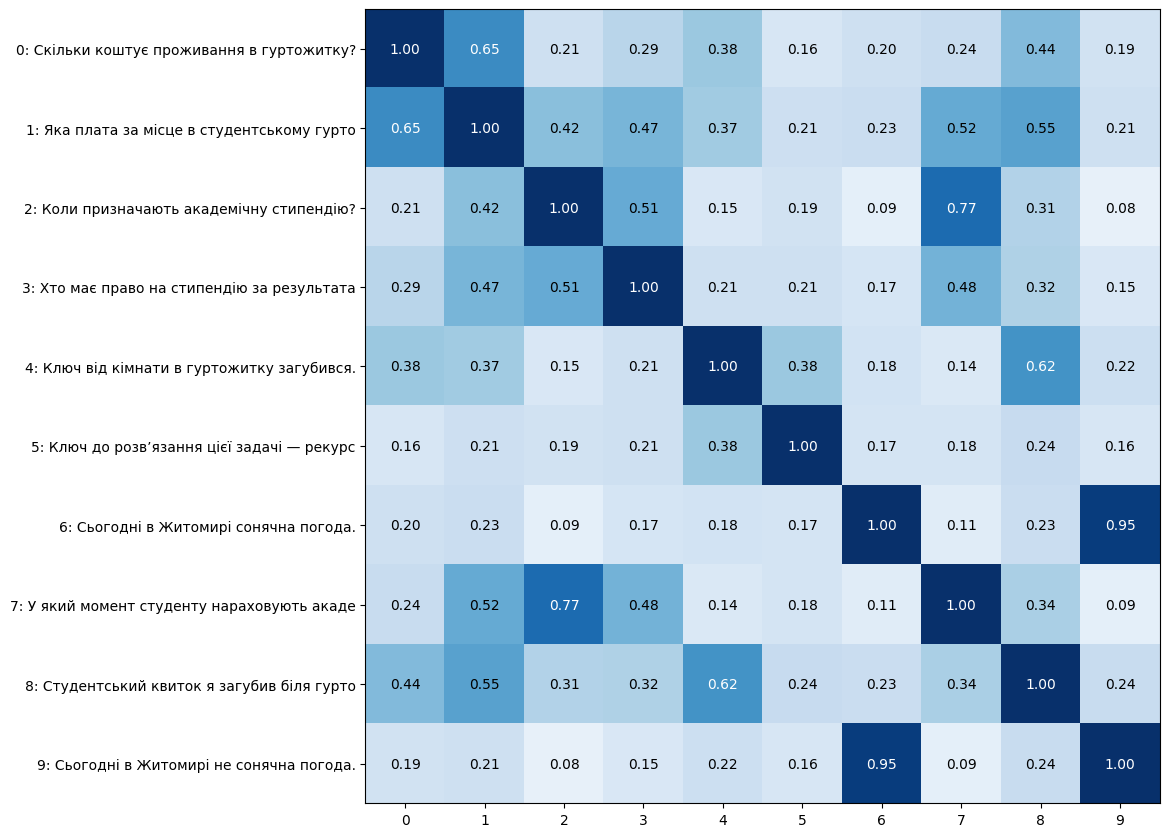

In [39]:
# Питання 5: додаємо до матриці подібності три власні речення
my_sentences = [
    "У який момент студенту нараховують академічну стипендію?",  # 7: перефразування речення 2
    "Студентський квиток я загубив біля гуртожитку.",            # 8: спільне слово «гуртожиток» з 0, інший зміст
    "Сьогодні в Житомирі не сонячна погода.",                    # 9: заперечення речення 6
]
show_similarity_matrix(uni_sentences + my_sentences, figsize=(11, 9))

### 5. Три власні речення в матриці подібності

Додано три речення (номери 7–9 у матриці вище):
- **7. «У який момент студенту нараховують академічну стипендію?»** — перефразування речення 2;
- **8. «Студентський квиток я загубив біля гуртожитку.»** — спільне слово «гуртожиток» з реченням 0, але інший зміст;
- **9. «Сьогодні в Житомирі не сонячна погода.»** — заперечення речення 6.

| Пара | Подібність | Коментар |
|---|---|---|
| 7 ↔ 2 (перефразування) | **0.77** | Найвища подібність до свого «оригіналу», навіть вища, ніж у пари перефразувань з демо (0 ↔ 1: 0.65). Модель добре розпізнає той самий зміст, висловлений іншими словами («призначають» ↔ «нараховують») |
| 8 ↔ 0 (спільне слово «гуртожиток») | **0.44** | Помірна подібність: спільне слово й тема «гуртожиток» дають певну близькість, але значно меншу, ніж у справжніх перефразувань |
| 8 ↔ 4 «Ключ від кімнати в гуртожитку загубився.» | **0.62** | Найвища подібність речення 8, і це логічно: обидва речення про те, що **людина щось загубила в/біля гуртожитку**. Тобто модель ловить зміст ситуації («загубив річ»), а не лише окреме слово |
| 9 ↔ 6 (заперечення) | **0.95** ❗ | Майже як у однакових речень, хоча зміст **протилежний** |

**Висновки:**
1. Перефразування модель розпізнає добре: зміст важливіший за конкретні слова.
2. Одне спільне слово дає помірну подібність, а схожа ситуація — значно вищу.
3. **Заперечення модель майже не помічає:** «сонячна» і «не сонячна» погода для неї майже однакові (0.95). Ембединг описує, **про що** текст (погода в Житомирі), а не чи є твердження істинним чи хибним. Для пошуку це небезпечно: на питання «Чи можна…» пошук однаково знайде і фрагмент «можна», і фрагмент «не можна». Тому остаточну відповідь має формувати мовна модель, яка читає текст повністю, а не ембединг.

In [40]:
# Питання 9: три власні питання і одне, на яке в документах немає відповіді
show("Який розмір стипендії ректора?", chunk_embeddings)                     # очікуємо 344
show("Скільки разів можна перескласти екзамен?", chunk_embeddings)           # очікуємо 275
show("Що вважається академічним плагіатом?", chunk_embeddings)               # очікуємо 1199
show("Скільки коштує парковка біля університету?", chunk_embeddings)         # відповіді немає

Запит: Який розмір стипендії ректора?
  0.63  [344] Положення про стипендію ректора
        ЗМІСТ 1. Загальні положення……………………………….. 3 2. Порядок призначення стипендії………………… 3 ЗМІСТ 1. Загальні положення……………………………….. 3 2. Порядок призначен…
  0.60  [340] Правила призначення академічних стипендій
        ращих з них за успіхи у навчанні, участь у громадській, спортивній і науковій діяльності наказом ректора Житомирської політехніки утворюються стипенді…
  0.58  [340] Правила призначення академічних стипендій
        ням наступних змін в оплаті праці на відповідних посадах), а саме: • викладача – для аспірантів; • доцента – для докторантів. Розмір стипендії доктора…

Запит: Скільки разів можна перескласти екзамен?
  0.49  [3320] ОПП F2 «Інженерія програмного забезпечення» (бакалавр), редакція 2025 року
         має право визнати та перезарахувати не більше ніж 120 кредитів ЄКТС, отриманих в межах попередньої освітньої програми підготовки молодшого бакалавра …
  0.47  [277] Положення п

### 9. Три власні питання до документів університету + питання без відповіді

| Питання | Очікуваний документ | Топ-3 фрагменти (подібність, документ) | Правильний у топ-3? |
|---|---|---|---|
| Який розмір стипендії ректора? | 344 | **0.63 [344]**, 0.60 [340], 0.58 [340] | ✅ на 1-му місці |
| Скільки разів можна перескласти екзамен? | 275 | 0.49 [3320], 0.47 [277], 0.43 [3329] | ❌ не потрапив |
| Що вважається академічним плагіатом? | 1199 | **0.80 [1199]**, 0.74 [1199], 0.67 [1199] | ✅ усі три з Кодексу |
| *Скільки коштує парковка біля університету?* | *немає відповіді* | 0.52 [348], 0.50 [348], 0.47 [348] | — (знайдено фрагменти про гуртожитки) |

**Аналіз:**
- **Плагіат (0.80)** і **стипендія ректора (0.63)** знайдено правильно: у запитах є ті самі ключові поняття, що й у документах («академічний плагіат», «стипендія ректора»).
- **Перескладання екзамену** — промах. Замість Положення про оцінювання (275) знайдено освітні програми (3320, 3329) з фрагментом «перезарахувати не більше ніж 120 кредитів» і Положення про вибіркові дисципліни (277). Модель «зачепилася» за схожі слова («перезарахувати», «повторний вибір»), а в документі 275 перескладання, імовірно, описане іншими словами («ліквідація академічної заборгованості»). Подібність найкращого фрагмента лише 0.49, і це сигнал невпевненості.
- **Питання без відповіді** (парковка) все одно повернуло 3 фрагменти, бо пошук **завжди повертає k найближчих**. Найкраща подібність **0.52**, помітно нижча, ніж у вдалих пошуків (0.63 і 0.80).

**Порівняння подібностей:** для питання без відповіді найкраща подібність (0.52) нижча, ніж для правильних знахідок (0.63, 0.80), але **вища**, ніж для питання про перескладання (0.49), на яке відповідь у документах є. Тобто **за подібністю не можна надійно відрізнити** «відповіді немає» від «відповідь є, але погано знайдена»: універсального порогу немає. Тому рішення «відповіді немає» має приймати мовна модель, прочитавши знайдені фрагменти (демо 2).

In [41]:
# Питання 10: порівнюємо пошук без назви документа і з назвою
def top_docs(query, embeddings, k=3):
    return [chunks[i]["doc_id"] for i, _ in search(query, embeddings, k)]

my_questions = [
    ("Коли потрібно внести оплату за проживання?", "348"),
    ("Хто призначає стипендію ректора?", "344"),
    ("Скільки кредитів ЄКТС має освітня програма?", "3320"),
    ("Скільки триває виробнича практика?", "291"),
    ("Що робити, якщо мене звинуватили у списуванні?", "1199"),
]
for q, expected in my_questions:
    print(f"{q}\n  очікуємо {expected} | без назви: {top_docs(q, chunk_embeddings)} | з назвою: {top_docs(q, titled_embeddings)}")

# Фрагмент, який знаходиться лише з назвою документа
q, expected = my_questions[0]
i_titled = search(q, titled_embeddings, 1)[0][0]
print("\nНайкращий фрагмент з назвою документа:", chunks[i_titled]["doc_id"], documents[chunks[i_titled]["doc_id"]]["title"])
print(chunks[i_titled]["text"][:400])

Коли потрібно внести оплату за проживання?
  очікуємо 348 | без назви: ['348', '348', '348'] | з назвою: ['348', '348', '348']
Хто призначає стипендію ректора?
  очікуємо 344 | без назви: ['340', '344', '344'] | з назвою: ['344', '344', '344']
Скільки кредитів ЄКТС має освітня програма?
  очікуємо 3320 | без назви: ['3329', '3320', '3320'] | з назвою: ['3329', '3320', '3320']
Скільки триває виробнича практика?
  очікуємо 291 | без назви: ['291', '291', '275'] | з назвою: ['291', '291', '291']
Що робити, якщо мене звинуватили у списуванні?
  очікуємо 1199 | без назви: ['1199', '1199', '1199'] | з назвою: ['277', '277', '1199']

Найкращий фрагмент з назвою документа: 348 Положення про користування гуртожитками
Університету згідно з виставленими рахунками. 5.2. Студент вносить авансовий платіж оплати за 1 семестр (5 місяців), включаючи і час своєї відсутності (відпустка, хвороба, відрядження і т.п.) 100 відсотків розміру, визначеної у рахунку- повідомленні до 1 вересня поточного року, а з

### 10. Чому дописування назви документа на початок фрагмента покращує пошук? Приклад фрагмента, який без назви втрачає зміст

**Чому допомагає.** Документ ділиться на фрагменти по 1000 символів, і фрагмент із середини документа часто **не містить слів, які пояснюють, про що весь документ**. Назва документа додає кожному фрагменту цей «глобальний контекст», і його ембединг стає ближчим до питань на тему документа.

**Приклад фрагмента, який без назви втрачає зміст** (документ 348):
> «…Університету згідно з виставленими рахунками. 5.2. Студент вносить авансовий платіж оплати за 1 семестр (5 місяців), включаючи і час своєї відсутності (відпустка, хвороба, відрядження і т.п.) 100 відсотків розміру, визначеної у рахунку-повідомленні до 1 вересня поточного року, а за 2 семестр (5 місяців) — до 1 лютого…»

У фрагменті **жодного разу немає слова «гуртожиток»**: з тексту незрозуміло, за що платить студент, за навчання чи за проживання. Лише назва «Положення про користування гуртожитками» робить зрозумілим, що це оплата за гуртожиток. У розділі 9 це видно в числах: подібність запиту «До якої дати платити за гуртожиток?» до цього фрагмента зросла з **0.51 до 0.76**, і він випередив фрагмент про тишу (0.59), який без назви був вище (0.61). З назвами документів знайдено **9 з 9** контрольних питань.

**Власні питання:**

| Питання | Очікуємо | Без назви | З назвою |
|---|---|---|---|
| Коли потрібно внести оплату за проживання? | 348 | 348, 348, 348 | 348, 348, 348 |
| Хто призначає стипендію ректора? | 344 | **340**, 344, 344 | **344**, 344, 344 ✅ покращення |
| Скільки кредитів ЄКТС має освітня програма? | 3320 | 3329, 3320, 3320 | 3329, 3320, 3320 |
| Скільки триває виробнича практика? | 291 | 291, 291, **275** | 291, 291, **291** ✅ покращення |
| Що робити, якщо мене звинуватили у списуванні? | 1199 | **1199, 1199, 1199** | **277, 277, 277** ❌ погіршення |

У двох питаннях назва покращила пошук: правильний документ піднявся на перше місце (стипендія ректора) або витіснив сторонній (практика). Для освітньої програми обидва варіанти знаходять і стару (3329), і нову (3320) редакцію з майже однаковою назвою, і назва їх не розрізняє.

**Але назва може й шкодити:** на питання про списування без назви знайдено правильний Кодекс академічної доброчесності (1199), а з назвою — «Положення про порядок та умови обрання здобувачами вищої освіти навчальних дисциплін» (277). Назва однакова для всіх фрагментів документа й «перетягує» ембединг у бік загальної теми документа, тож для коротких фрагментів вона може переважити їхній власний зміст. Тому назву варто додавати, але оцінювати ефект на наборі питань. Кращі варіанти — коротший заголовок, назва розділу замість назви документа або згенерований моделлю короткий контекст для кожного фрагмента (contextual retrieval).